In [9]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.stats
import random

In [27]:
def func(x):
    return np.exp(-x**2+x)

def q(x):
    return 3*np.exp(-(x-1)**2/2)

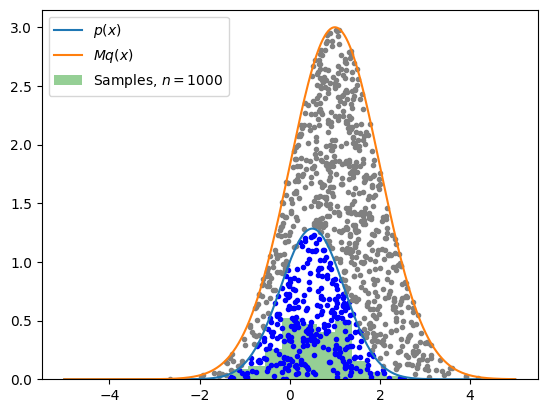

In [34]:
rng = np.random.default_rng(42)

n=1000
x_plot = np.linspace(-5,5,500)

x_r = rng.normal(1, 1, n)          # <-- sample from q, not uniform
u = rng.uniform(0, q(x_r))        # u ~ U(0, Mq(x)), vectorized

points_good=[[],[]]
points_bad=[[],[]]

for i in range(0,n):
    if u[i] < func(x_r[i]):
        points_good[0].append(x_r[i])
        points_good[1].append(u[i])
    else:
        points_bad[0].append(x_r[i])
        points_bad[1].append(u[i])

plt.plot(x_plot, func(x_plot), label='$p(x)$')
plt.plot(x_plot,q(x_plot), label='$Mq(x)$')
plt.hist(points_good[0], density=True, alpha=0.5, label=rf"Samples, $n={n}$")

plt.scatter(points_good[0],points_good[1], color='blue', marker='.')
plt.scatter(points_bad[0],points_bad[1], color='grey',marker='.')

plt.legend()
plt.show()